# TMDB Movie Data Analysis using Pandas and APIs
**By:** Molo Munyansanga

---

## Project Overview
This project builds a movie data analysis pipeline using Python and Pandas: fetching movie data from the TMDB API, cleaning and transforming it, and calculating key performance indicators (KPIs).

**How this notebook is organized:** the code for each step lives in the `src/` folder (`fetch.py`, `clean.py`, `analysis.py`, `visualize.py`). This notebook imports those functions and walks through the results step by step. To run the whole pipeline without the notebook, run `python main.py` from the project folder.

### Setup

In [1]:
# Let the notebook find the src/ folder (it is one level above this notebook)
import sys
sys.path.append("..")

import pandas as pd
import numpy as np

from src import fetch, clean, analysis, visualize

# Show all columns when displaying DataFrames
pd.set_option("display.max_columns", None)

## Project Steps
### Step 1: Fetch Movie Data from API
- Choose a movie database API (e.g., TMDb)
- Fetch movies with the following IDs:

```python
movie_id = [
    0, 299534, 19995, 140607, 299536, 597, 135397,
    420818, 24428, 168259, 99861, 284054, 12445,
    181808, 330457, 351286, 109445, 321612, 260513
]
```
- Store the data as a Pandas DataFrame

`fetch.load_or_fetch()` loads the saved raw data from `data/raw/movies_raw.json` if it exists. Otherwise it fetches the movies from the API and saves them. Movie ID `0` doesn't exist on TMDB, so the API returns an error for it and it is skipped.

In [2]:
# Use refresh=True to fetch fresh data from the API instead of the saved file
raw_df = fetch.load_or_fetch()
raw_df.head()

Loading raw data...


,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,credits
0,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534,tt4154796,[US],en,Avengers: Endgame,After the devastating events of Avengers: Infi...,82.5666,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg,"[{'id': 420, 'logo_path': '/hUzeosd33nzE5MCNsZ...","[{'iso_3166_1': 'US', 'name': 'United States o...",2019-04-24,2938567784,181,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.246,29073,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
1,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995,tt0499549,[US],en,Avatar,"In the 22nd century, a paraplegic Marine is di...",39.3685,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,"[{'id': 444, 'logo_path': None, 'name': 'Dune ...","[{'iso_3166_1': 'US', 'name': 'United States o...",2009-12-16,2923706026,162,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.611,34888,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
2,False,/8BTsTfln4jlQrLXUBquXJ0ASQy9.jpg,"{'id': 10, 'name': 'Star Wars Collection', 'po...",245000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",http://www.starwars.com/films/star-wars-episod...,140607,tt2488496,[US],en,Star Wars: The Force Awakens,Thirty years after defeating the Galactic Empi...,28.0028,/wqnLdwVXoBjKibFRR5U3y0aDUhs.jpg,"[{'id': 1, 'logo_path': '/tlVSws0RvvtPBwViUyOF...","[{'iso_3166_1': 'US', 'name': 'United States o...",2015-12-15,2068223624,136,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Every generation has a story.,Star Wars: The Force Awakens,False,7.240,21044,"{'cast': [{'adult': False, 'gender': 1, 'id': ..."
3,False,/mDfJG3LC3Dqb67AZ52x3Z0jU0uB.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",300000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 28, '...",https://www.marvel.com/movies/avengers-infinit...,299536,tt4154756,[US],en,Avengers: Infinity War,As the Avengers and their allies have continue...,84.6857,/7WsyChQLEftFiDOVTGkv3hFpyyt.jpg,"[{'id': 420, 'logo_path': '/hUzeosd33nzE5MCNsZ...","[{'iso_3166_1': 'US', 'name': 'United States o...",2018-04-25,2052415039,149,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,An entire universe. Once and for all.,Avengers: Infinity War,False,8.245,33217,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."
4,False,/sCzcYW9h55WcesOqA12cgEr9Exw.jpg,None,200000000,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n...",https://www.paramountmovies.com/movies/titanic,597,tt0120338,[US],en,Titanic,101-year-old Rose DeWitt Bukater tells the sto...,42.3436,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,"[{'id': 4, 'logo_path': '/jay6WcMgagAklUt7i9Eu...","[{'iso_3166_1': 'US', 'name': 'United States o...",1997-12-18,2264162353,194,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Nothing on earth could come between them.,Titanic,False,7.900,27940,"{'cast': [{'adult': False, 'gender': 2, 'id': ..."


### Step 2: Data Cleaning and Preprocessing
#### Data Preparation & Cleaning
1. Drop irrelevant columns: `['adult', 'imdb_id', 'original_title', 'video', 'homepage']`

In [3]:
df = clean.drop_irrelevant_columns(raw_df.copy())
df.columns

Index(['backdrop_path', 'belongs_to_collection', 'budget', 'genres', 'id',
       'origin_country', 'original_language', 'overview', 'popularity',
       'poster_path', 'production_companies', 'production_countries',
       'release_date', 'revenue', 'runtime', 'softcore', 'spoken_languages',
       'status', 'tagline', 'title', 'vote_average', 'vote_count', 'credits'],
      dtype='str')

2. Evaluate JSON-like columns: `['belongs_to_collection', 'genres', 'production_countries', 'production_companies', 'spoken_languages']`
3. Extract and clean key data points:
    - Collection name (`belongs_to_collection`)

In [4]:
# What the column looks like before cleaning
df["belongs_to_collection"][1]

{'id': 87096,
 'name': 'Avatar Collection',
 'poster_path': '/3C5brXxnBxfkeKWwA1Fh4xvy4wr.jpg',
 'backdrop_path': '/4uwX70EzaWVcGUXMtXPoexlNAff.jpg'}

In [5]:
df = clean.extract_collection(df)
df["belongs_to_collection"].head()

0    The Avengers Collection
1          Avatar Collection
2       Star Wars Collection
3    The Avengers Collection
4                        NaN
Name: belongs_to_collection, dtype: str

- Credits name (`credits`)

Clean the column into the names of the cast and the director(s), and count the size of the cast and crew:

In [6]:
df = clean.extract_credits(df)
df[["title", "cast", "cast_size", "director", "crew_size"]].head()

,title,cast,cast_size,director,crew_size
0,Avengers: Endgame,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,103,Anthony Russo|Joe Russo,613
1,Avatar,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,68,James Cameron,999
2,Star Wars: The Force Awakens,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driv...,99,J.J. Abrams,270
3,Avengers: Infinity War,Robert Downey Jr.|Chris Evans|Chris Hemsworth|...,69,Joe Russo|Anthony Russo,738
4,Titanic,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,116,James Cameron,271


- Genre names (`genres` → separate multiple genres with `|`)
- Spoken languages (`spoken_languages` → separate with `|`)
- Production countries (`production_countries` → separate with `|`)
- Production companies (`production_companies` → separate with `|`)

In [7]:
# What the column looks like before cleaning
df["production_countries"][3]

[{'iso_3166_1': 'US', 'name': 'United States of America'}]

In [8]:
df = clean.extract_names(df)
df[["genres", "spoken_languages", "production_countries", "production_companies"]].head()

,genres,spoken_languages,production_countries,production_companies
0,Adventure|Science Fiction|Action,English|日本語|,United States of America,Marvel Studios
1,Science Fiction|Action|Adventure,English|Español,United States of America|United Kingdom,Dune Entertainment|Lightstorm Entertainment|20...
2,Adventure|Action|Science Fiction,English,United States of America,Lucasfilm Ltd.|Bad Robot
3,Adventure|Action|Science Fiction,English|,United States of America,Marvel Studios
4,Drama|Romance,English|Français|Deutsch|svenska|Italiano|Pусский,United States of America,Paramount Pictures|20th Century Fox|Lightstorm...


4. Inspect extracted columns using `value_counts()` to identify anomalies

In [9]:
cols = ["belongs_to_collection", "genres", "spoken_languages", "production_countries", "production_companies"]
for col in cols:
    print(df[col].value_counts())
    print("----------------------")

belongs_to_collection
The Avengers Collection                4
Star Wars Collection                   2
Jurassic Park Collection               2
Frozen Collection                      2
Avatar Collection                      1
The Lion King (Reboot) Collection      1
The Fast and the Furious Collection    1
Black Panther Collection               1
Harry Potter Collection                1
The Incredibles Collection             1
Name: count, dtype: int64
----------------------
genres
Adventure|Action|Science Fiction             3
Science Fiction|Action|Adventure             2
Adventure|Science Fiction|Thriller           2
Action|Adventure|Science Fiction             2
Adventure|Science Fiction|Action             1
Drama|Romance                                1
Adventure|Drama|Family|Animation             1
Action|Crime|Thriller                        1
Adventure|Fantasy                            1
Family|Animation|Adventure|Comedy|Fantasy    1
Animation|Family|Adventure|Fantasy        

#### Handling Missing & Incorrect Data
5. Convert column datatypes:
    - `'budget'`, `'id'`, `'popularity'` → Numeric (set invalid values to `NaN`)
    - `'release_date'` → Convert to datetime

In [10]:
df = clean.convert_types(df)
df[["budget", "id", "popularity", "release_date"]].dtypes

budget                   int64
id                       int64
popularity             float64
release_date    datetime64[us]
dtype: object

**Observation:** `budget`, `id` and `popularity` were already numeric, so the conversion doesn't change them. `release_date` is now a datetime.

6. Replace unrealistic values:
    - Budget / Revenue / Runtime = `0` → Replace with `NaN`
    - Movies with `vote_count = 0` → their `vote_average` is set to `NaN`
    - `'overview'` and `'tagline'` → Replace known placeholders (e.g., `'No Data'`) with `NaN`

In [11]:
# Check how many values will be affected before replacing them
print("Budget = 0:", (df["budget"] == 0).sum())
print("Revenue = 0:", (df["revenue"] == 0).sum())
print("Runtime = 0:", (df["runtime"] == 0).sum())
print("Vote count = 0:", (df["vote_count"] == 0).sum())
print("Overview placeholders:", df["overview"].isin(["No Data", ""]).sum())
print("Tagline placeholders:", df["tagline"].isin(["No Data", ""]).sum())

Budget = 0: 0
Revenue = 0: 0
Runtime = 0: 0
Vote count = 0: 0
Overview placeholders: 0
Tagline placeholders: 0


In [12]:
df = clean.replace_unrealistic_values(df)

**Observation:** There don't appear to be unrealistic values among these columns, so the replacement doesn't change anything in this dataset.

- Convert `'budget'` and `'revenue'` to million USD

In [13]:
df = clean.convert_to_millions(df)
df[["title", "budget_musd", "revenue_musd"]].head()

,title,budget_musd,revenue_musd
0,Avengers: Endgame,356.0,2938.57
1,Avatar,237.0,2923.71
2,Star Wars: The Force Awakens,245.0,2068.22
3,Avengers: Infinity War,300.0,2052.42
4,Titanic,200.0,2264.16


7. Remove duplicates and drop rows with unknown `'id'` or `'title'`
8. Keep only rows where at least 10 columns have non-`NaN` values

In [14]:
# Look at the rows that have NaN values before removing anything
rows_with_nulls = np.any(df.isna(), axis=1)
print("Rows with at least one NaN:", rows_with_nulls.sum())
df[rows_with_nulls]

Rows with at least one NaN: 2


,backdrop_path,belongs_to_collection,genres,id,origin_country,original_language,overview,popularity,poster_path,production_companies,production_countries,release_date,runtime,softcore,spoken_languages,status,tagline,title,vote_average,vote_count,cast_size,crew_size,cast,director,budget_musd,revenue_musd
4,/sCzcYW9h55WcesOqA12cgEr9Exw.jpg,NaN,Drama|Romance,597,[US],en,101-year-old Rose DeWitt Bukater tells the sto...,42.3436,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,Paramount Pictures|20th Century Fox|Lightstorm...,United States of America,1997-12-18,194,False,English|Français|Deutsch|svenska|Italiano|Pусский,Released,Nothing on earth could come between them.,Titanic,7.900,27940,116,271,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,James Cameron,200.0,2264.16
16,/uU1Mt4JWhDvl4vKb3AfxNsorkoM.jpg,NaN,Family|Fantasy|Romance,321612,[US],en,A live-action adaptation of Disney's version o...,23.7646,/hKegSKIDep2ewJWPUQD7u0KqFIp.jpg,Walt Disney Pictures|Mandeville Films,United States of America,2017-03-16,129,False,Français|English,Released,Be our guest.,Beauty and the Beast,6.969,16235,139,169,Emma Watson|Dan Stevens|Luke Evans|Josh Gad|Ke...,Bill Condon,160.0,1266.12


In [15]:
rows_before = len(df)
df = clean.remove_bad_rows(df)
print("Rows removed:", rows_before - len(df))

Rows removed: 0


**Observation:** There are no duplicates or missing ids/titles, and the rows with `NaN` values still have more than 10 non-`NaN` columns, so all rows are kept.

9. Filter to include only `'Released'` movies, then drop `'status'`

In [16]:
df["status"].value_counts()

status
Released    18
Name: count, dtype: int64

In [17]:
df = clean.filter_released(df)

#### Reorder & Finalize DataFrame
10. Reorder columns
11. Reset index

In [18]:
df = clean.reorder_columns(df)
df.head()

,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size
0,299534,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,The Avengers Collection,en,356.0,2938.57,Marvel Studios,United States of America,29073,8.246,82.5666,181,After the devastating events of Avengers: Infi...,English|日本語|,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,103,Anthony Russo|Joe Russo,613
1,19995,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,Avatar Collection,en,237.0,2923.71,Dune Entertainment|Lightstorm Entertainment|20...,United States of America|United Kingdom,34888,7.611,39.3685,162,"In the 22nd century, a paraplegic Marine is di...",English|Español,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,68,James Cameron,999
2,140607,Star Wars: The Force Awakens,Every generation has a story.,2015-12-15,Adventure|Action|Science Fiction,Star Wars Collection,en,245.0,2068.22,Lucasfilm Ltd.|Bad Robot,United States of America,21044,7.240,28.0028,136,Thirty years after defeating the Galactic Empi...,English,/wqnLdwVXoBjKibFRR5U3y0aDUhs.jpg,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driv...,99,J.J. Abrams,270
3,299536,Avengers: Infinity War,An entire universe. Once and for all.,2018-04-25,Adventure|Action|Science Fiction,The Avengers Collection,en,300.0,2052.42,Marvel Studios,United States of America,33217,8.245,84.6857,149,As the Avengers and their allies have continue...,English|,/7WsyChQLEftFiDOVTGkv3hFpyyt.jpg,Robert Downey Jr.|Chris Evans|Chris Hemsworth|...,69,Joe Russo|Anthony Russo,738
4,597,Titanic,Nothing on earth could come between them.,1997-12-18,Drama|Romance,NaN,en,200.0,2264.16,Paramount Pictures|20th Century Fox|Lightstorm...,United States of America,27940,7.900,42.3436,194,101-year-old Rose DeWitt Bukater tells the sto...,English|Français|Deutsch|svenska|Italiano|Pусский,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,116,James Cameron,271


In [19]:
# Save the clean data to data/processed/movies_clean.csv
clean.save_clean_data(df)

Saved clean data to C:\Users\GADGET STORE\Downloads\AmaliTech\TMDB-Movie-Data-Analysis\data\processed\movies_clean.csv


**Note:** all the steps above can also be run in one line with `df = clean.clean_data(raw_df)`. That's what `main.py` does.

#### Before vs. After Cleaning
A quick summary of what the cleaning changed.

In [20]:
clean.compare_before_after(raw_df, df)

,Metric,Before,After
0,Rows,18,18
1,Columns,28,22
2,Missing values (total),2,2
3,Duplicate ids,0,0


In [21]:
# Missing values per column after cleaning
clean.missing_values(df)

belongs_to_collection    2
dtype: int64

In [22]:
# Summary statistics of the raw numeric columns (budget and revenue are still in USD here)
raw_df[["budget", "revenue", "runtime", "vote_count", "vote_average", "popularity"]].describe()

,budget,revenue,runtime,vote_count,vote_average,popularity
count,1.800000e+01,1.800000e+01,18.000000,18.000000,18.000000,18.000000
mean,2.137778e+08,1.699656e+09,138.000000,21751.055556,7.398000,39.525678
std,6.195972e+07,5.391077e+08,23.847555,8747.467832,0.530559,19.430304
min,1.250000e+08,1.243226e+09,102.000000,10535.000000,6.520000,22.319400
25%,1.625000e+08,1.336184e+09,125.250000,14582.000000,7.116750,26.535350
50%,2.000000e+08,1.484542e+09,135.500000,21543.000000,7.263500,29.063000
75%,2.430000e+08,1.957196e+09,147.500000,27258.250000,7.827750,47.788150
max,3.560000e+08,2.938568e+09,194.000000,40111.000000,8.246000,84.685700


In [23]:
# Summary statistics of the clean numeric columns (budget and revenue in million USD)
df.describe()

,id,release_date,budget_musd,revenue_musd,vote_count,vote_average,popularity,runtime,cast_size,crew_size
count,18.000000,18,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000
mean,192258.444444,2015-04-07 12:00:00,213.777778,1699.657222,21751.055556,7.398000,39.525678,138.000000,79.944444,390.666667
min,597.000000,1997-12-18 00:00:00,125.000000,1243.230000,10535.000000,6.520000,22.319400,102.000000,20.000000,43.000000
25%,102257.000000,2014-03-24 06:00:00,162.500000,1336.185000,14582.000000,7.116750,26.535350,125.250000,61.000000,212.000000
50%,175033.500000,2016-07-30 12:00:00,200.000000,1484.540000,21543.000000,7.263500,29.063000,135.500000,72.000000,279.500000
75%,299535.500000,2018-05-26 12:00:00,243.000000,1957.200000,27258.250000,7.827750,47.788150,147.500000,106.000000,606.250000
max,420818.000000,2019-11-20 00:00:00,356.000000,2938.570000,40111.000000,8.246000,84.685700,194.000000,139.000000,999.000000
std,132476.949284,NaN,61.959717,539.107846,8747.467832,0.530559,19.430304,23.847555,30.988560,260.024659


**Observation:** Only the column `belongs_to_collection` is empty for standalone movies, which is expected.

### Exploratory Data Analysis (EDA)
Before calculating the KPIs, explore the clean data to understand what the dataset looks like.

#### Summary statistics

In [24]:
df[["budget_musd", "revenue_musd", "vote_count", "vote_average", "popularity", "runtime"]].describe().round(2)

,budget_musd,revenue_musd,vote_count,vote_average,popularity,runtime
count,18.00,18.00,18.00,18.00,18.00,18.00
mean,213.78,1699.66,21751.06,7.40,39.53,138.00
std,61.96,539.11,8747.47,0.53,19.43,23.85
min,125.00,1243.23,10535.00,6.52,22.32,102.00
25%,162.50,1336.18,14582.00,7.12,26.54,125.25
50%,200.00,1484.54,21543.00,7.26,29.06,135.50
75%,243.00,1957.20,27258.25,7.83,47.79,147.50
max,356.00,2938.57,40111.00,8.25,84.69,194.00


**Observation:** Every movie in this dataset is a major blockbuster. Revenues range from about `$1.24 billion` (*Incredibles 2*) to `$2.94 billion` (*Avengers: Endgame*), and budgets from `$125 million` to `$356 million`. Ratings fall in a narrow band between 6.5 and 8.2. Any conclusions from this analysis apply to top-grossing movies, not movies in general.

#### Distributions of key columns

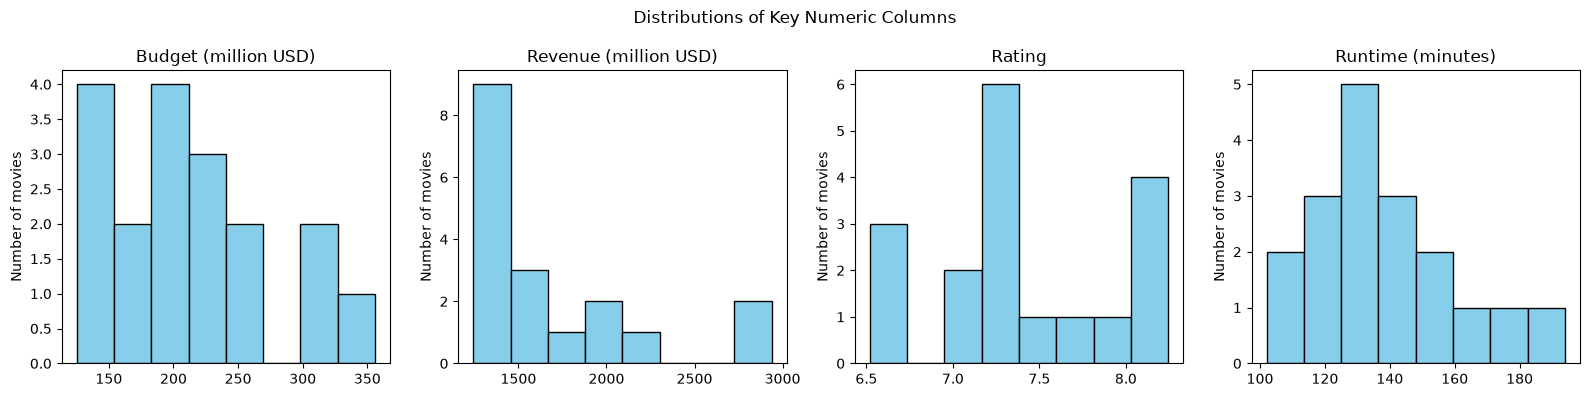

In [25]:
visualize.plot_distributions(df)

**Observation:** Revenue is right-skewed, with half the movies (9) earning between $1.2B and $1.45B and two outliers near $2.9B. Most movies are rated between 7.2 and 7.4 and run 120–140 minutes.

#### Genres

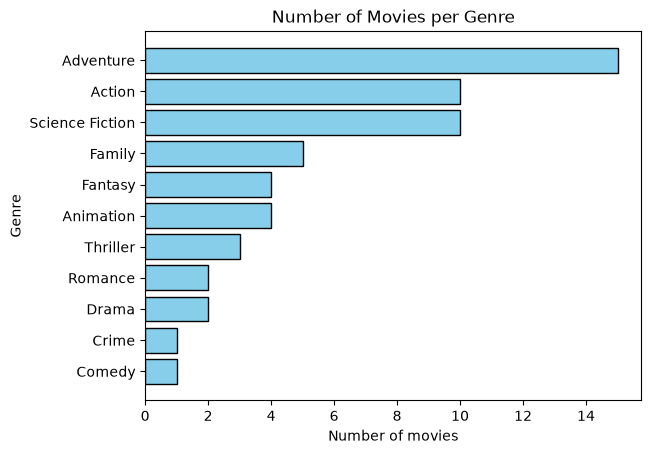

In [26]:
visualize.plot_genre_counts(df)

**Observation:** Adventure is the most common genre (15 of 18 movies), followed by Action and Science Fiction (10 each), while Comedy and Crime appear only once.

#### Release years

In [27]:
df["release_date"].dt.year.value_counts().sort_index()

release_date
1997    1
2009    1
2011    1
2012    1
2013    1
2015    4
2017    2
2018    4
2019    3
Name: count, dtype: int64

**Observation:** The movies were released in 1997, 2009, and every year from 2011 to 2019, so the dataset is mostly recent releases.

#### Franchise vs. standalone count

In [28]:
df["belongs_to_collection"].notna().value_counts().rename({True: "Franchise", False: "Standalone"})

belongs_to_collection
Franchise     16
Standalone     2
Name: count, dtype: int64

**Observation:** 16 of the 18 movies belong to a franchise. Only *Titanic* and *Beauty and the Beast* are standalone, so the franchise vs. standalone comparison later is based on just 2 standalone movies.

#### Correlations between numeric columns

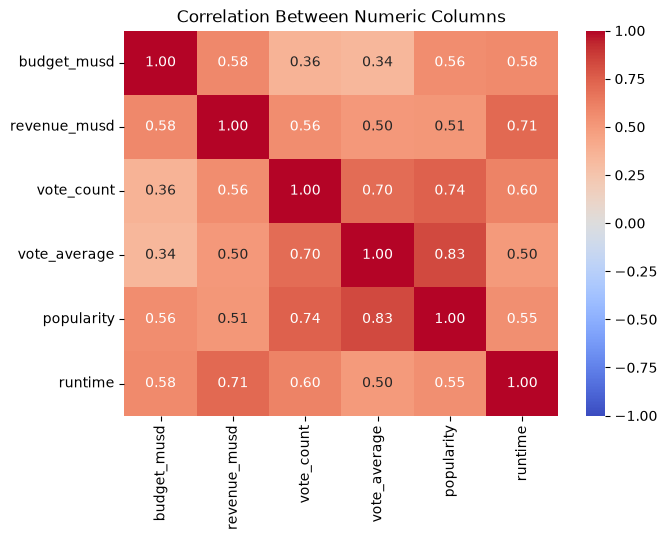

In [29]:
visualize.plot_correlations(df)

**Observation:** All numeric columns are positively correlated, with the strongest link between popularity and rating (0.83). Budget has only a moderate link with revenue (0.58) and a weak one with rating (0.34).

### Step 3: KPI Implementation & Analysis
#### Identify the Best/Worst Performing Movies
> The User-Defined Function (UDF) `analysis.rank_movies()` is used to streamline the ranking operations.

First, add the profit and ROI columns:

In [30]:
df = analysis.add_profit_and_roi(df)
df[["title", "budget_musd", "revenue_musd", "profit_musd", "roi"]].head()

,title,budget_musd,revenue_musd,profit_musd,roi
0,Avengers: Endgame,356.0,2938.57,2582.57,8.254410
1,Avatar,237.0,2923.71,2686.71,12.336329
2,Star Wars: The Force Awakens,245.0,2068.22,1823.22,8.441714
3,Avengers: Infinity War,300.0,2052.42,1752.42,6.841400
4,Titanic,200.0,2264.16,2064.16,11.320800


1. Filter and rank movies based on:
    - Highest Revenue

In [31]:
analysis.rank_movies(df, "revenue_musd")

,title,revenue_musd
0,Avengers: Endgame,2938.57
1,Avatar,2923.71
4,Titanic,2264.16
2,Star Wars: The Force Awakens,2068.22
3,Avengers: Infinity War,2052.42
5,Jurassic World,1671.54
6,The Lion King,1662.02
7,The Avengers,1518.82
8,Furious 7,1515.40
13,Frozen II,1453.68


**Observation:** *Avengers: Endgame* (\$2.94B) and *Avatar* (\$2.92B) are almost tied for the highest revenue, well ahead of *Titanic* in third (\$2.26B).

- Highest Budget

In [32]:
analysis.rank_movies(df, "budget_musd")

,title,budget_musd
0,Avengers: Endgame,356.0
3,Avengers: Infinity War,300.0
12,Star Wars: The Last Jedi,300.0
6,The Lion King,260.0
2,Star Wars: The Force Awakens,245.0
1,Avatar,237.0
9,Avengers: Age of Ultron,235.0
7,The Avengers,220.0
10,Black Panther,200.0
4,Titanic,200.0


- Highest Profit (Revenue - Budget)

In [33]:
analysis.rank_movies(df, "profit_musd")

,title,profit_musd
1,Avatar,2686.71
0,Avengers: Endgame,2582.57
4,Titanic,2064.16
2,Star Wars: The Force Awakens,1823.22
3,Avengers: Infinity War,1752.42
5,Jurassic World,1521.54
6,The Lion King,1402.02
8,Furious 7,1325.40
13,Frozen II,1303.68
7,The Avengers,1298.82


- Lowest Profit (Revenue - Budget)

In [34]:
analysis.rank_movies(df, "profit_musd", ascending=True)

,title,profit_musd
12,Star Wars: The Last Jedi,1034.41
17,Incredibles 2,1043.23
16,Beauty and the Beast,1106.12
15,Frozen,1124.22
14,Jurassic World: Fallen Kingdom,1140.47
10,Black Panther,1149.93
9,Avengers: Age of Ultron,1170.40
11,Harry Potter and the Deathly Hallows: Part 2,1216.51
7,The Avengers,1298.82
13,Frozen II,1303.68


**Observation:** Even the least profitable movie, *Star Wars: The Last Jedi*, made over \$1 billion in profit. No movie in this dataset lost money.

- Highest ROI (Revenue / Budget) — only movies with Budget ≥ 10M

In [35]:
budget_10m = analysis.filter_min_budget(df)
analysis.rank_movies(budget_10m, "roi")

,title,roi
1,Avatar,12.336329
4,Titanic,11.320800
5,Jurassic World,11.143600
11,Harry Potter and the Deathly Hallows: Part 2,10.732080
13,Frozen II,9.691200
15,Frozen,8.494800
2,Star Wars: The Force Awakens,8.441714
0,Avengers: Endgame,8.254410
8,Furious 7,7.975789
16,Beauty and the Beast,7.913250


- Lowest ROI — only movies with Budget ≥ 10M

In [36]:
analysis.rank_movies(budget_10m, "roi", ascending=True)

,title,roi
12,Star Wars: The Last Jedi,4.448033
9,Avengers: Age of Ultron,5.980426
17,Incredibles 2,6.216150
6,The Lion King,6.392385
10,Black Panther,6.749650
3,Avengers: Infinity War,6.841400
7,The Avengers,6.903727
14,Jurassic World: Fallen Kingdom,7.708647
16,Beauty and the Beast,7.913250
8,Furious 7,7.975789


**Observation:** *Avatar* has both the highest profit and the highest ROI (12.3x its budget). The lowest ROI, *Star Wars: The Last Jedi*, still earned 4.4x its budget.

- Most Voted Movies

In [37]:
analysis.rank_movies(df, "vote_count")

,title,vote_count
7,The Avengers,40111
1,Avatar,34888
3,Avengers: Infinity War,33217
0,Avengers: Endgame,29073
4,Titanic,27940
9,Avengers: Age of Ultron,25213
10,Black Panther,24128
11,Harry Potter and the Deathly Hallows: Part 2,22606
5,Jurassic World,22042
2,Star Wars: The Force Awakens,21044


- Highest Rated Movies — only movies with ≥ 10 votes

In [38]:
votes_10 = analysis.filter_min_votes(df)
analysis.rank_movies(votes_10, "vote_average")

,title,vote_average
0,Avengers: Endgame,8.246
3,Avengers: Infinity War,8.245
11,Harry Potter and the Deathly Hallows: Part 2,8.081
7,The Avengers,8.081
4,Titanic,7.900
1,Avatar,7.611
17,Incredibles 2,7.452
10,Black Panther,7.361
9,Avengers: Age of Ultron,7.278
15,Frozen,7.249


- Lowest Rated Movies — only movies with ≥ 10 votes

In [39]:
analysis.rank_movies(votes_10, "vote_average", ascending=True)

,title,vote_average
14,Jurassic World: Fallen Kingdom,6.520
5,Jurassic World,6.703
12,Star Wars: The Last Jedi,6.732
16,Beauty and the Beast,6.969
6,The Lion King,7.089
13,Frozen II,7.200
8,Furious 7,7.207
2,Star Wars: The Force Awakens,7.240
15,Frozen,7.249
9,Avengers: Age of Ultron,7.278


- Most Popular Movies

In [40]:
analysis.rank_movies(df, "popularity")

,title,popularity
3,Avengers: Infinity War,84.6857
0,Avengers: Endgame,82.5666
7,The Avengers,58.5907
11,Harry Potter and the Deathly Hallows: Part 2,53.2473
9,Avengers: Age of Ultron,49.6030
4,Titanic,42.3436
10,Black Panther,40.0632
1,Avatar,39.3685
12,Star Wars: The Last Jedi,29.1022
15,Frozen,29.0238


**Observation:** The Avengers movies dominate the vote counts and popularity rankings, and *Avengers: Endgame* and *Infinity War* are also the two highest-rated movies.

#### Advanced Movie Filtering & Search Queries
2. Filter the dataset for specific queries:
    - **Search 1:** Find the best-rated Science Fiction Action movies starring Bruce Willis (sorted by Rating — highest to lowest)

In [41]:
analysis.search_bruce_willis(df)

,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size,profit_musd,roi


**Observation:** There are no movies starring Bruce Willis among the movies in the data.

- **Search 2:** Find movies starring Uma Thurman, directed by Quentin Tarantino (sorted by runtime — shortest to longest)

In [42]:
analysis.search_uma_thurman_tarantino(df)

,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size,profit_musd,roi


**Observation:** There are no movies starring Uma Thurman among the movies in the data.

#### Franchise vs. Standalone Movie Performance
3. Compare movie franchises (`belongs_to_collection`) vs. standalone movies in terms of:
    - Mean Revenue
    - Median ROI
    - Mean Budget Raised
    - Mean Popularity
    - Mean Rating

In [43]:
analysis.franchise_vs_standalone(df)

,Metric,Franchise,Standalone
0,Mean Revenue (M USD),1691.471875,1765.140000
1,Median ROI,7.842218,9.617025
2,Mean Budget (M USD),218.000000,180.000000
3,Mean Popularity,40.334625,33.054100
4,Mean Rating,7.393438,7.434500


**Observation:** Franchise movies had bigger budgets (\$218M vs. \$180M on average) and higher popularity. Standalone movies had slightly higher mean revenue and median ROI, but with only 2 standalone movies (*Titanic* and *Beauty and the Beast*) this comparison isn't conclusive.

#### Most Successful Franchises & Directors
4. Find the **Most Successful Movie Franchises** based on:
    - Total number of movies in franchise
    - Total & Mean Budget
    - Total & Mean Revenue
    - Mean Rating

In [44]:
franchises = analysis.franchise_summary(df)
franchises

,movie_count,total_budget_musd,mean_budget_musd,total_revenue_musd,mean_revenue_musd,mean_rating
belongs_to_collection,,,,,,
The Avengers Collection,4,1111.0,277.75,7915.21,1978.8025,7.9625
Star Wars Collection,2,545.0,272.50,3402.63,1701.3150,6.9860
Jurassic Park Collection,2,320.0,160.00,2982.01,1491.0050,6.6115
Avatar Collection,1,237.0,237.00,2923.71,2923.7100,7.6110
Frozen Collection,2,300.0,150.00,2727.90,1363.9500,7.2245
The Lion King (Reboot) Collection,1,260.0,260.00,1662.02,1662.0200,7.0890
The Fast and the Furious Collection,1,190.0,190.00,1515.40,1515.4000,7.2070
Black Panther Collection,1,200.0,200.00,1349.93,1349.9300,7.3610
Harry Potter Collection,1,125.0,125.00,1341.51,1341.5100,8.0810


**Observation:** The Avengers Collection is the most successful franchise, with 4 movies, \$7.9 billion in total revenue, and the highest mean rating of any franchise with more than one movie (7.96).

In [45]:
# The same table sorted by a different metric, e.g. number of movies
franchises.sort_values(by="movie_count", ascending=False)

,movie_count,total_budget_musd,mean_budget_musd,total_revenue_musd,mean_revenue_musd,mean_rating
belongs_to_collection,,,,,,
The Avengers Collection,4,1111.0,277.75,7915.21,1978.8025,7.9625
Star Wars Collection,2,545.0,272.50,3402.63,1701.3150,6.9860
Jurassic Park Collection,2,320.0,160.00,2982.01,1491.0050,6.6115
Frozen Collection,2,300.0,150.00,2727.90,1363.9500,7.2245
Avatar Collection,1,237.0,237.00,2923.71,2923.7100,7.6110
The Lion King (Reboot) Collection,1,260.0,260.00,1662.02,1662.0200,7.0890
The Fast and the Furious Collection,1,190.0,190.00,1515.40,1515.4000,7.2070
Black Panther Collection,1,200.0,200.00,1349.93,1349.9300,7.3610
Harry Potter Collection,1,125.0,125.00,1341.51,1341.5100,8.0810


5. Find the **Most Successful Directors** based on:
    - Total Number of Movies Directed
    - Total Revenue
    - Mean Rating

In [46]:
directors = analysis.director_summary(df)
directors

,movie_count,total_revenue_musd,mean_rating
director_split,,,
James Cameron,2,5187.87,7.7555
Anthony Russo,2,4990.99,8.2455
Joe Russo,2,4990.99,8.2455
Joss Whedon,2,2924.22,7.6795
Jennifer Lee,2,2727.90,7.2245
Chris Buck,2,2727.90,7.2245
J.J. Abrams,1,2068.22,7.2400
Colin Trevorrow,1,1671.54,6.7030
Jon Favreau,1,1662.02,7.0890


In [47]:
directors.sort_values(by="mean_rating", ascending=False)

,movie_count,total_revenue_musd,mean_rating
director_split,,,
Anthony Russo,2,4990.99,8.2455
Joe Russo,2,4990.99,8.2455
David Yates,1,1341.51,8.0810
James Cameron,2,5187.87,7.7555
Joss Whedon,2,2924.22,7.6795
Brad Bird,1,1243.23,7.4520
Ryan Coogler,1,1349.93,7.3610
J.J. Abrams,1,2068.22,7.2400
Jennifer Lee,2,2727.90,7.2245


**Observation:** James Cameron has the highest total revenue (\$5.19B from *Avatar* and *Titanic*). Anthony and Joe Russo, who co-directed both *Avengers: Infinity War* and *Endgame*, have the highest mean rating (8.25).

### Step 4: Data Visualization
- Revenue vs. Budget Trends

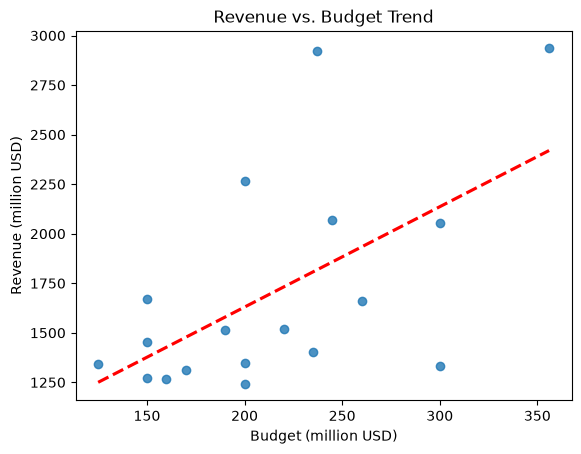

In [48]:
visualize.plot_revenue_vs_budget(df)

**Observation:** Revenue tends to rise with budget, but the points are widely scattered. Avatar earned about `$2.9B` on a `$237M` budget, while a `$300M` movie earned only about $1.3B.

- ROI Distribution by Genre

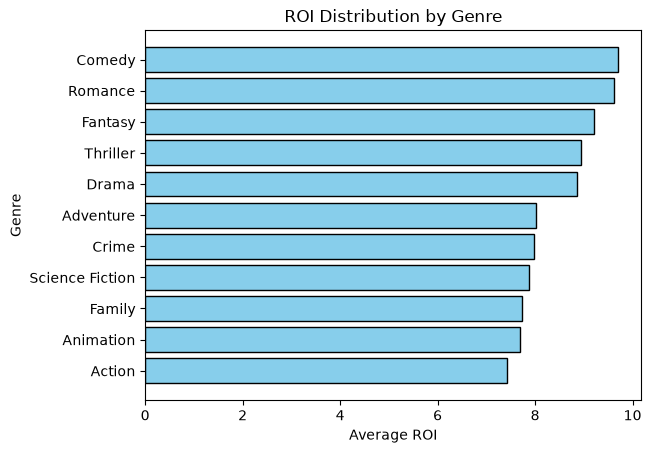

In [49]:
visualize.plot_roi_by_genre(df)

**Observation:** Comedy and Romance have the highest average ROI (about 9.7) and Action the lowest (about 7.4). However, Comedy and Romance are based on only 1–2 movies each, so these averages are less reliable.

- Popularity vs. Rating

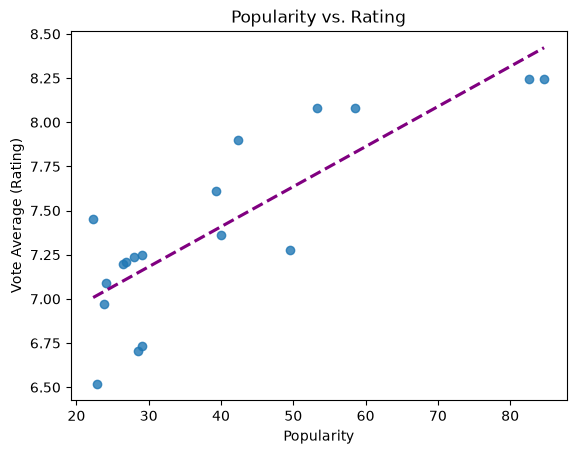

In [50]:
visualize.plot_popularity_vs_rating(df)

**Observation:** More popular movies tend to have higher ratings, with the two most popular movies (the latest Avengers films) also rated highest at about 8.25.

- Yearly Trends in Box Office Performance

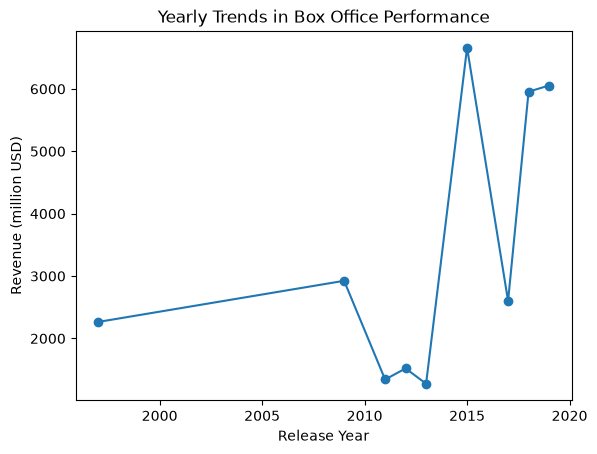

In [51]:
visualize.plot_yearly_revenue(df)

**Observation:** Total revenue peaks in 2015 (about `$6.7B`) and 2018–2019 (about `$6B`), mainly because more of the dataset’s movies were released in those years. The chart reflects how many movies came out each year more than a real box office trend.

- Comparison of Franchise vs. Standalone Success

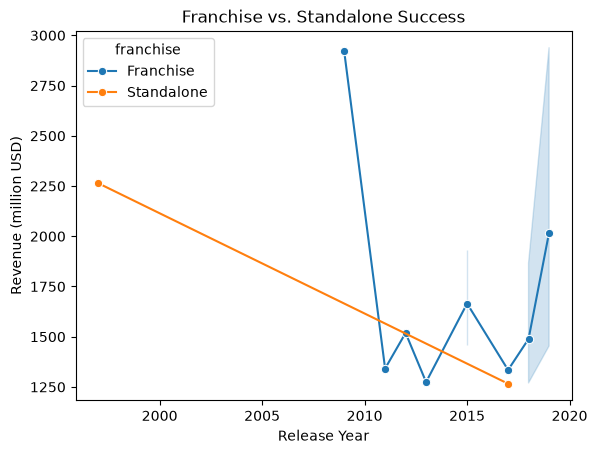

In [52]:
visualize.plot_franchise_vs_standalone(df)

**Observation:** The standalone line connects only two movies (Titanic in 1997 and Beauty and the Beast in 2017), so it doesn’t show a real trend. Franchise movies make up every other release from 2009 onwards.